# Relatório — IDS multiclasse para SOME/IP (C1)

Este experimento investiga a detecção de intrusão **multiclasse** para o protocolo
SOME/IP (classes: *normal, DoS, Fuzzy, MITM-single, MITM-multi*). A investigação segue
a linha de raciocínio abaixo, com **toda a implementação detalhada**:

- **Parte A** — aplicamos as **12 features** do baseline (projetadas para detecção
  *binária*) ao problema multiclasse e medimos o resultado.
- **Diagnóstico** — analisamos **onde** a detecção falha e propomos **4 features** novas.
- **Parte B** — reimplementamos com **16 features** (12 + 4) e medimos de novo.
- **Parte C** — comparamos 12 × 16 (ganho de detecção) e o **custo** (latência).

As métricas de latência são lidas em CPU, 1 núcleo, no cenário de uma ECU de *gateway*.


## 0. Preparação do ambiente


In [1]:
# Bootstrap: garante repo + dependências (funciona local, na VM ou no Colab)
import os, sys
REPO = "someip-ids-multiclass-contentext"
def in_repo(): return os.path.exists("run_experiment.py") and os.path.isdir("src")
if not in_repo() and os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
if not in_repo() and os.path.isdir(REPO): os.chdir(REPO)
if not in_repo():
    os.system("git lfs install; git clone https://github.com/GuilhermeFrick/%s.git" % REPO); os.chdir(REPO)
os.system("%s -m pip install -q numpy scapy 'xgboost==3.3.0' scikit-learn matplotlib pandas" % sys.executable)
MAX_PACKETS = None   # None = dataset completo (14.2M); ex. 50000 p/ um teste rápido
print("cwd:", os.getcwd(), "| MAX_PACKETS:", MAX_PACKETS)


cwd: /home/ubuntu/someip-ids-multiclass-contentext | MAX_PACKETS: None


In [2]:
# Imports comuns e caracterização da máquina (os números de latência dependem dela)
import time, json, socket, platform, numpy as np
from collections import defaultdict, deque
from dataclasses import dataclass, field
from scapy.utils import RawPcapReader
print("Plataforma :", platform.platform())
print("Processador:", platform.processor() or platform.machine())
print("CPUs       :", os.cpu_count())
import shutil; DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
print("device     :", DEVICE)


Plataforma : Linux-6.17.0-1017-aws-x86_64-with-glibc2.39
Processador: x86_64
CPUs       : 8
device     : cpu


## 1. Dados
Dataset público de tráfego SOME/IP (figshare): uma captura benigna e seis com ataques
injetados (DoS, Fuzzy, MITM de nó único e de múltiplos nós), ~14,2 M pacotes em PCAP.


In [3]:
if not os.path.exists("data/pcap/benign_traffic.pcap"):
    print("baixando PCAPs (~1.9 GB)..."); os.system("%s scripts/download_pcaps.py" % sys.executable)
print(sorted(os.listdir("data/pcap")) if os.path.isdir("data/pcap") else "AUSENTE")


['benign_traffic.pcap', 'dos_noti_flood.pcap', 'fuzzy_sd_offer_rand_noti(1).pcap', 'fuzzy_sd_offer_rand_noti(2).pcap', 'fuzzy_sd_offer_rand_noti(3).pcap', 'mitm_multi_attacker.pcap', 'mitm_single_attacker.pcap']


## 2. Implementação — motor de parsing e features
A seguir, todo o motor que transforma um PCAP cru em vetores de *features*: o **parser**
SOME/IP, o **modelo de bytes** (base das features de conteúdo) e o **extrator** das 16
*features* (12 do baseline + 4 propostas). Em Parte A usamos as 12; em Parte B, as 16.


### 2.1 Modelo de bytes (conteúdo do *payload*)
Aprende, no tráfego benigno, a distribuição de cada *byte* por posição do *payload* (com
suavização de Laplace). Dá origem às features de conteúdo: *log-likelihood*, entropia
cruzada e distância de Hamming entre pacotes.


In [4]:
class ByteModel:
    """Distribuição posicional de bytes do payload benigno (Laplace)."""
    def __init__(self, L, alpha=1.0):
        self.L = int(L); self.alpha = float(alpha)
        self._counts = np.zeros((self.L, 256), dtype=np.float64); self.logP = None
    def update(self, payload):                      # acumula contagens (treino, benigno)
        k = min(len(payload), self.L)
        if k == 0: return
        self._counts[np.arange(k), np.frombuffer(payload[:k], np.uint8)] += 1.0
    def finalize(self):                             # P_i(b) com Laplace -> log P
        P = (self._counts + self.alpha) / (self._counts.sum(1, keepdims=True) + self.alpha*256.0)
        self.logP = np.log(P); return self
    def loglik(self, payload):                      # soma log P nas posições (quão "esperado")
        k = min(len(payload), self.L)
        if k == 0: return 0.0
        return float(self.logP[np.arange(k), np.frombuffer(payload[:k], np.uint8)].sum())
    def cross_entropy(self, payload):               # -(1/k) soma log P (independe do tamanho)
        k = min(len(payload), self.L)
        if k == 0: return 0.0
        return float(-self.logP[np.arange(k), np.frombuffer(payload[:k], np.uint8)].sum()/k)

def hamming(a, b):                                  # mudança de conteúdo entre dois payloads
    if not a and not b: return 0
    n = min(len(a), len(b))
    if n == 0: return max(len(a), len(b))
    aa = np.frombuffer(a[:n], np.uint8); bb = np.frombuffer(b[:n], np.uint8)
    return int(np.count_nonzero(aa != bb) + abs(len(a) - len(b)))


### 2.2 Parser SOME/IP
Lê o frame Ethernet cru → IP → TCP/UDP → cabeçalho SOME/IP, separando o *payload* e
identificando mensagens de *Service Discovery* (SD). **Sem usar os identificadores de
cabeçalho como features** (apenas para separar as camadas).


In [5]:
SD_PORT = 30490; ETH_IPV4 = b"\x08\x00"; MT_NOTIFICATION = 0x02
SD_FIND = 0x00; SD_OFFER = 0x01; RELAY_SERVICE = 0x100B
def _ip(b): return socket.inet_ntoa(b)

@dataclass(slots=True)
class Pkt:
    ts: float = 0.0; src: str = ""; dst: str = ""; proto: int = 0
    sport: int = 0; dport: int = 0; ip_len: int = 0
    is_someip: bool = False; is_sd: bool = False
    service_id: int = -1; method_id: int = -1; msg_type: int = -1; client_id: int = -1
    pl_l4: bytes = b""; pl_someip: bytes = b""; pl_sd: bytes = b""
    sd_entries: tuple = field(default_factory=tuple)

def parse(raw, ts=0.0):
    if raw[12:14] != ETH_IPV4: return None          # só IPv4
    ihl = (raw[14] & 0x0F) * 4; proto = raw[23]
    ip_len = int.from_bytes(raw[16:18], "big"); l4 = 14 + ihl
    p = Pkt(ts=ts, src=_ip(raw[26:30]), dst=_ip(raw[30:34]), proto=proto, ip_len=ip_len)
    if proto == 17:                                 # UDP
        p.sport = int.from_bytes(raw[l4:l4+2], "big"); p.dport = int.from_bytes(raw[l4+2:l4+4], "big"); off = l4 + 8
    elif proto == 6:                                # TCP
        p.sport = int.from_bytes(raw[l4:l4+2], "big"); p.dport = int.from_bytes(raw[l4+2:l4+4], "big")
        off = l4 + (raw[l4+12] >> 4) * 4
    else:
        return None
    p.pl_l4 = raw[off:]
    if len(p.pl_l4) < 16: return p                  # sem cabeçalho SOME/IP completo
    p.service_id = int.from_bytes(p.pl_l4[0:2], "big"); p.method_id = int.from_bytes(p.pl_l4[2:4], "big")
    p.client_id = int.from_bytes(p.pl_l4[8:10], "big"); p.msg_type = p.pl_l4[14]
    p.is_someip = True; body = p.pl_l4[16:]
    if p.dport == SD_PORT or p.sport == SD_PORT or p.service_id == 0xFFFF:
        p.is_sd = True; p.pl_sd = body; p.sd_entries = _parse_sd_entries(body)
    else:
        p.pl_someip = body
    return p

def _parse_sd_entries(body):
    if len(body) < 12: return ()
    try:
        end = 8 + int.from_bytes(body[4:8], "big"); entries = []; i = 8
        while i + 16 <= min(end, len(body)):
            entries.append((body[i], int.from_bytes(body[i+4:i+6], "big"),
                            int.from_bytes(body[i+6:i+8], "big"), int.from_bytes(body[i+9:i+12], "big")))
            i += 16
        return tuple(entries)
    except Exception:
        return ()

def flow_key(p): return (p.src, p.dst, p.sport, p.dport, p.proto)


### 2.3 Rótulos e treino do modelo de bytes
As classes vêm do arquivo (DoS, Fuzzy, MITM single/multi). Por pacote, o rótulo é
atribuído **pelo nó atacante** (IP de origem fora do conjunto benigno). Os byte-models
são treinados **só no tráfego benigno**.


In [6]:
NORMAL, DOS, FUZZY, MITM_SINGLE, MITM_MULTI = 0, 1, 2, 3, 4
CLASSES = ["normal", "dos", "fuzzy", "mitm_single", "mitm_multi"]; NCLS = 5
L = {"someip": 64, "sd": 80, "l4": 64}
BENIGN_FILE = "benign_traffic.pcap"
ATTACK_FILES = {"dos_noti_flood.pcap": DOS,
                "fuzzy_sd_offer_rand_noti(1).pcap": FUZZY, "fuzzy_sd_offer_rand_noti(2).pcap": FUZZY,
                "fuzzy_sd_offer_rand_noti(3).pcap": FUZZY,
                "mitm_multi_attacker.pcap": MITM_MULTI, "mitm_single_attacker.pcap": MITM_SINGLE}
def _ts(meta):
    try: return meta.sec + meta.usec * 1e-6
    except Exception: return 0.0

def fit_bytemodels(pcap_dir, alpha=1.0, max_packets=None):
    models = {k: ByteModel(L[k], alpha) for k in L}; benign_ips = set(); n = 0
    for raw, meta in RawPcapReader(os.path.join(pcap_dir, BENIGN_FILE)):
        n += 1
        if max_packets and n > max_packets: break
        p = parse(raw)
        if p is None: continue
        benign_ips.add(p.src)
        if p.pl_l4: models["l4"].update(p.pl_l4)
        if p.is_sd and p.pl_sd: models["sd"].update(p.pl_sd)
        elif p.pl_someip: models["someip"].update(p.pl_someip)
    for m in models.values(): m.finalize()
    return models, benign_ips


### 2.4 Extração das *features* (12 do baseline + 4 propostas)
O `FeatureStreamer` calcula, pacote a pacote, o vetor de *features* mantendo estado por
fluxo e por origem. As **12 primeiras** são as do baseline; as **4 últimas**, as propostas.
Em Parte A usamos as 12; em Parte B, as 16.


In [7]:
FEATURE_NAMES = [
    # --- 12 do baseline (conteúdo + temporização, por camada) ---
    "ip_time_interval", "someip_loglik", "sd_loglik", "l4_loglik",
    "someip_entropy", "sd_entropy", "l4_entropy",
    "someip_change", "sd_change", "l4_change", "ip_len_change", "l4_len_change",
    # --- 4 PROPOSTAS (comportamentais) ---
    "repeat_rate", "someip_len", "l4_len", "src_payload_div",
]
# As 4 features PROPOSTAS (índices 12–15):
#   12 repeat_rate (payload repetition) | 13 someip_len + 14 l4_len (absolute size)
#   | 15 src_payload_div (source diversity)
PROPOSTAS_IDX = [12, 13, 14, 15]
IDX_12 = list(range(12))          # baseline (Parte A): só as 12
IDX_16 = list(range(16))          # proposto  (Parte B): as 12 + 4 propostas

class FeatureStreamer:
    def __init__(self):
        self.last = {}
        self.recent_pld = defaultdict(lambda: deque(maxlen=5))     # por fluxo  (repeat_rate)
        self.src_pld = defaultdict(lambda: deque(maxlen=1000))     # por origem (src_payload_div)
    def step(self, p, models):
        fk = flow_key(p); st = self.last.get(fk)
        # --- 12 do baseline: temporização, mudanças e conteúdo (byte-model) ---
        if st is None:
            iat = 0.0; ip_len_chg = 0; l4_len_chg = 0; someip_chg = sd_chg = l4_chg = 0
        else:
            iat = p.ts - st["ts"]; ip_len_chg = p.ip_len - st["ip_len"]
            l4_len_chg = len(p.pl_l4) - len(st["l4"]); l4_chg = hamming(p.pl_l4, st["l4"])
            someip_chg = hamming(p.pl_someip, st["someip"]) if (p.pl_someip or st["someip"]) else 0
            sd_chg = hamming(p.pl_sd, st["sd"]) if (p.pl_sd or st["sd"]) else 0
        someip_ll = models["someip"].loglik(p.pl_someip) if p.pl_someip else 0.0
        sd_ll = models["sd"].loglik(p.pl_sd) if p.pl_sd else 0.0
        l4_ll = models["l4"].loglik(p.pl_l4) if p.pl_l4 else 0.0
        someip_h = models["someip"].cross_entropy(p.pl_someip) if p.pl_someip else 0.0
        sd_h = models["sd"].cross_entropy(p.pl_sd) if p.pl_sd else 0.0
        l4_h = models["l4"].cross_entropy(p.pl_l4) if p.pl_l4 else 0.0
        # --- 4 PROPOSTAS ---
        h = self.recent_pld[fk]
        repeat_rate = (sum(1 for q in h if q == p.pl_someip)/len(h)) if (h and p.pl_someip) else 0.0   # (1) payload repetition
        h.append(p.pl_someip)
        someip_len = float(len(p.pl_someip)); l4_len = float(len(p.pl_l4))                             # (2) absolute size
        wp = self.src_pld[p.src]
        if p.pl_someip: wp.append(p.pl_someip)
        src_payload_div = (len(set(wp))/len(wp)) if len(wp) > 1 else 0.0                               # (3) source diversity
        self.last[fk] = {"ts": p.ts, "ip_len": p.ip_len, "l4": p.pl_l4, "someip": p.pl_someip, "sd": p.pl_sd}
        return (iat, someip_ll, sd_ll, l4_ll, someip_h, sd_h, l4_h, someip_chg, sd_chg, l4_chg,
                ip_len_chg, l4_len_chg, repeat_rate, someip_len, l4_len, src_payload_div)

def extract_file(path, models, attack_type=NORMAL, benign_ips=None, max_packets=None):
    streamer = FeatureStreamer(); benign_ips = benign_ips or set(); X, y = [], []; n = 0
    for raw, meta in RawPcapReader(path):
        n += 1
        if max_packets and n > max_packets: break
        p = parse(raw, _ts(meta))
        if p is None: continue
        X.append(streamer.step(p, models))
        y.append(attack_type if (attack_type != NORMAL and p.src not in benign_ips) else NORMAL)
    return X, y


### 2.5 Extração do dataset inteiro
Treina os byte-models no benigno e extrai as 16 *features* de todos os arquivos
(cronometrado). A normalização é *min-max* por coluna. Resultado reaproveitado por A e B.


In [8]:
t0 = time.perf_counter(); MODELS, BENIGN_IPS = fit_bytemodels("data/pcap", max_packets=MAX_PACKETS)
print("byte-models treinados em %.1fs | IPs benignos: %d" % (time.perf_counter()-t0, len(BENIGN_IPS)))
files = [(BENIGN_FILE, NORMAL)] + list(ATTACK_FILES.items())
Xp, yp, COUNTS, t_ext = [], [], [], 0.0
for fname, atk in files:
    t0 = time.perf_counter(); Xf, yf = extract_file("data/pcap/"+fname, MODELS, atk, BENIGN_IPS, MAX_PACKETS)
    t_ext += time.perf_counter()-t0
    Xp.append(np.asarray(Xf, np.float64)); yp.append(np.asarray(yf, np.int64)); COUNTS.append(len(yf))
    print("  %-38s pkts=%9d" % (fname, len(yf)))
Xraw = np.concatenate(Xp); Y = np.concatenate(yp); del Xp, yp
XMIN = Xraw.min(0); XMAX = Xraw.max(0); RNG = np.where(XMAX > XMIN, XMAX-XMIN, 1.0)
XN = ((Xraw - XMIN)/RNG).astype(np.float32); del Xraw
EXT_US = t_ext/Y.size*1e6
print("\nEXTRAÇÃO: %d pacotes em %.1fs -> %.2f us/pacote" % (Y.size, t_ext, EXT_US))
print("por classe:", dict(zip(CLASSES, np.bincount(Y, minlength=5).tolist())))


byte-models treinados em 18.4s | IPs benignos: 9


  benign_traffic.pcap                    pkts=  2193802


  dos_noti_flood.pcap                    pkts=  1864530


  fuzzy_sd_offer_rand_noti(1).pcap       pkts=  2197113


  fuzzy_sd_offer_rand_noti(2).pcap       pkts=  1304154


  fuzzy_sd_offer_rand_noti(3).pcap       pkts=  2223650


  mitm_multi_attacker.pcap               pkts=  2412529


  mitm_single_attacker.pcap              pkts=  2037576



EXTRAÇÃO: 14233354 pacotes em 372.6s -> 26.18 us/pacote
por classe: {'normal': 12578355, 'dos': 306944, 'fuzzy': 560052, 'mitm_single': 360510, 'mitm_multi': 427493}


## 3. Funções do experimento
Split **temporal** (70% cronológicos de cada arquivo → treino) e as rotinas de treino,
avaliação e figuras. São aplicadas, mais abaixo, às 12 e depois às 16 *features*.


In [9]:
import matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

def temporal_split(counts, frac=0.70):
    tr, te, s = [], [], 0
    for c in counts:
        cut = s + int(c*frac); tr.append(np.arange(s, cut)); te.append(np.arange(cut, s+c)); s += c
    return np.concatenate(tr), np.concatenate(te)
ITR, ITE = temporal_split(COUNTS); Y_TE = Y[ITE]

PARAMS = dict(objective="multi:softprob", num_class=NCLS, n_estimators=300, max_depth=8,
              learning_rate=0.3, tree_method="hist", device=DEVICE, max_bin=256,
              n_jobs=-1, eval_metric="mlogloss")

def train_eval(idx, label):
    """Treina XGBoost nas features `idx` e avalia no teste temporal."""
    names = [FEATURE_NAMES[i] for i in idx]
    clf = XGBClassifier(**PARAMS); clf.fit(XN[np.ix_(ITR, idx)], Y[ITR])
    proba = clf.predict_proba(XN[np.ix_(ITE, idx)]); pred = proba.argmax(1)
    rep = classification_report(Y_TE, pred, target_names=CLASSES, digits=4, output_dict=True)
    print("[%s] macro-F1 = %.4f | accuracy = %.4f" % (label, rep["macro avg"]["f1-score"], rep["accuracy"]))
    return dict(label=label, idx=idx, names=names, clf=clf, proba=proba, pred=pred,
                rep=rep, macro_f1=rep["macro avg"]["f1-score"], acc=rep["accuracy"])

def metrics_table(res):
    r = res["rep"]
    return pd.DataFrame([{"classe": c, "precision": r[c]["precision"], "recall": r[c]["recall"],
                          "F1": r[c]["f1-score"]} for c in CLASSES]).round(4)

def plot_cm(res):
    cm = confusion_matrix(Y_TE, res["pred"]); cmn = cm/cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NCLS)); ax.set_yticks(range(NCLS))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusão — %s" % res["label"])
    for i in range(NCLS):
        for j in range(NCLS):
            ax.text(j, i, "%.1f%%" % (cmn[i, j]*100), ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    fig.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

def plot_importance(res):
    sc = res["clf"].get_booster().get_score(importance_type="gain")
    imp = np.array([sc.get("f%d" % i, 0.0) for i in range(len(res["idx"]))]); order = np.argsort(imp)
    plt.figure(figsize=(7, 5)); plt.barh([res["names"][i] for i in order], imp[order])
    plt.xlabel("Importância (gain)"); plt.title("Importância das features — %s" % res["label"])
    plt.tight_layout(); plt.show()

def plot_roc_pr(res):
    yb = label_binarize(Y_TE, classes=range(NCLS)); proba = res["proba"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, name in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(yb[:, i], proba[:, i]); s = max(len(fpr)//2000, 1)
        a1.plot(fpr[::s], tpr[::s], lw=1.4, label="%s (AUC=%.3f)" % (name, auc(fpr, tpr)))
        pr, rc, _ = precision_recall_curve(yb[:, i], proba[:, i]); s2 = max(len(rc)//2000, 1)
        a2.plot(rc[::s2], pr[::s2], lw=1.4, label="%s (AP=%.3f)" % (name, average_precision_score(yb[:, i], proba[:, i])))
    a1.plot([0, 1], [0, 1], "k--", lw=.6); a1.set_title("ROC — %s" % res["label"]); a1.legend(fontsize=7)
    a1.set_xlabel("FPR"); a1.set_ylabel("TPR"); a2.set_title("Precision-Recall — %s" % res["label"])
    a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.legend(fontsize=7); plt.tight_layout(); plt.show()


## 4. Parte A — detecção com as 12 *features* originais (baseline)
Primeira tentativa: aplicar diretamente as **12 *features* do baseline** (projetadas para
detecção binária normal×ataque) ao problema **multiclasse**.


### 4.1 Detecção


In [10]:
resA = train_eval(IDX_12, "12 features")


[12 features] macro-F1 = 0.7793 | accuracy = 0.9514


### 4.2 Métricas por classe


In [11]:
metrics_table(resA)


,classe,precision,recall,F1
0,normal,0.9511,0.9993,0.9746
1,dos,0.9927,0.7543,0.8572
2,fuzzy,0.9844,0.3768,0.5450
3,mitm_single,0.8934,0.9970,0.9423
4,mitm_multi,0.9916,0.4070,0.5771


### 4.3 Matriz de confusão — onde falha?


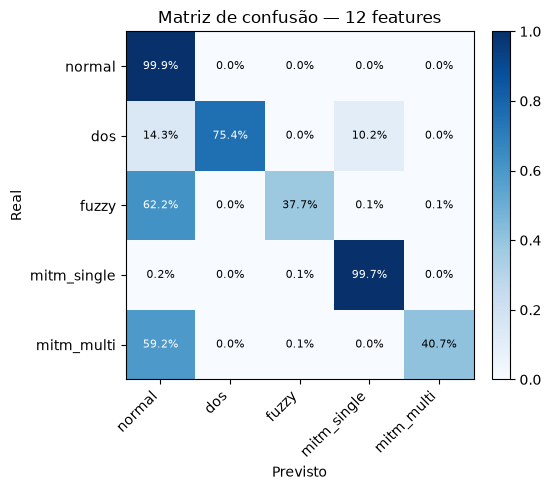

In [12]:
plot_cm(resA)


### 4.4 Importância das features


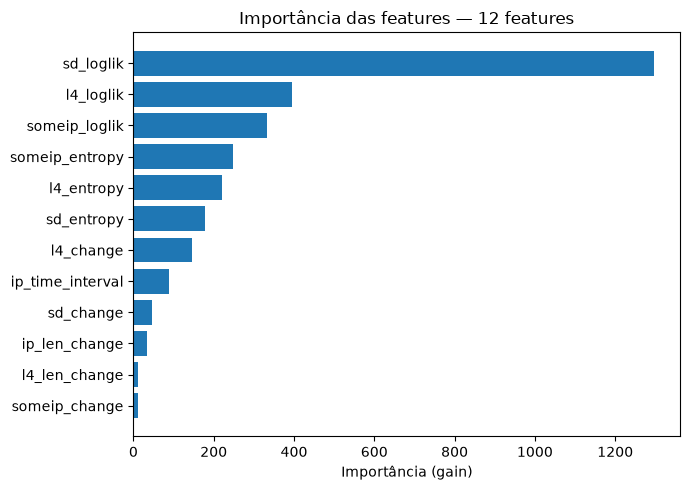

In [13]:
plot_importance(resA)


### 4.5 Curvas ROC / Precision-Recall


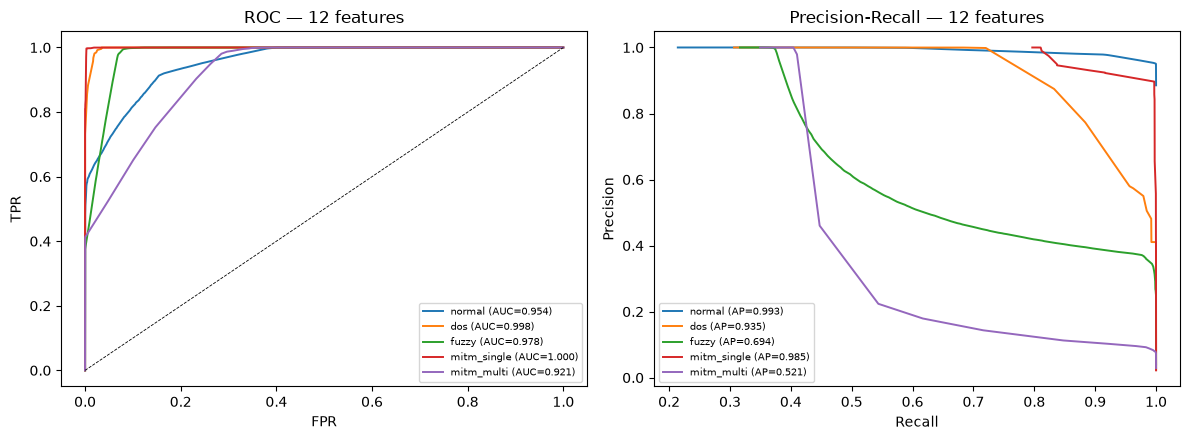

In [14]:
plot_roc_pr(resA)


## 5. Diagnóstico → as 4 *features* propostas
As 12 *features* dão um macro-F1 modesto: duas classes **colapsam** — o *Fuzzy* (conteúdo
aleatório que as estatísticas de *byte* não distinguem bem) e o *MITM-multi* (serviço
*relay* interposto). A matriz de confusão e a importância acima confirmam o problema.

Para atacar exatamente esses padrões, propomos **4 *features* comportamentais**:

- **`repeat_rate`** (repetição de *payload* na janela do fluxo) — separa o *Fuzzy*, que
  nunca repete conteúdo, do tráfego normal, que repete.
- **`someip_len` + `l4_len`** (*absolute size*) — tamanho absoluto do *payload*, que o
  *Fuzzy* e o *DoS* distorcem.
- **`src_payload_div`** (*source diversity*) — diversidade de *payloads* por origem, que
  denuncia o nó *relay* do *MITM-multi*.

A seguir, reimplementamos acrescentando essas 4 *features* (total 16).


## 6. Parte B — detecção com as 16 *features* (12 + 4 propostas)


### 6.1 Detecção


In [15]:
resB = train_eval(IDX_16, "16 features")


[16 features] macro-F1 = 0.9640 | accuracy = 0.9884


### 6.2 Métricas por classe


In [16]:
metrics_table(resB)


,classe,precision,recall,F1
0,normal,0.9998,0.9873,0.9935
1,dos,0.9937,0.9993,0.9965
2,fuzzy,0.9984,0.9992,0.9988
3,mitm_single,0.9862,1.0000,0.9930
4,mitm_multi,0.7260,0.9908,0.8380


### 6.3 Matriz de confusão


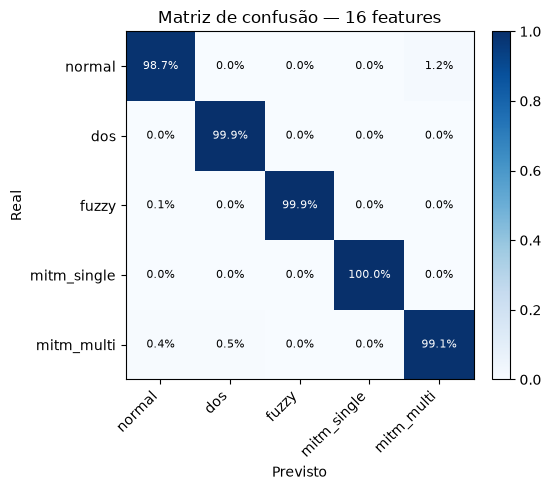

In [17]:
plot_cm(resB)


### 6.4 Importância das features
As *features* propostas aparecem entre as mais importantes.


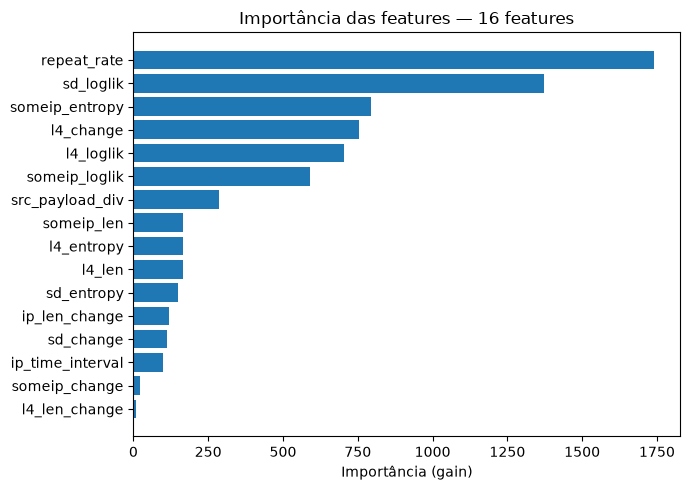

In [18]:
plot_importance(resB)


### 6.5 Curvas ROC / Precision-Recall


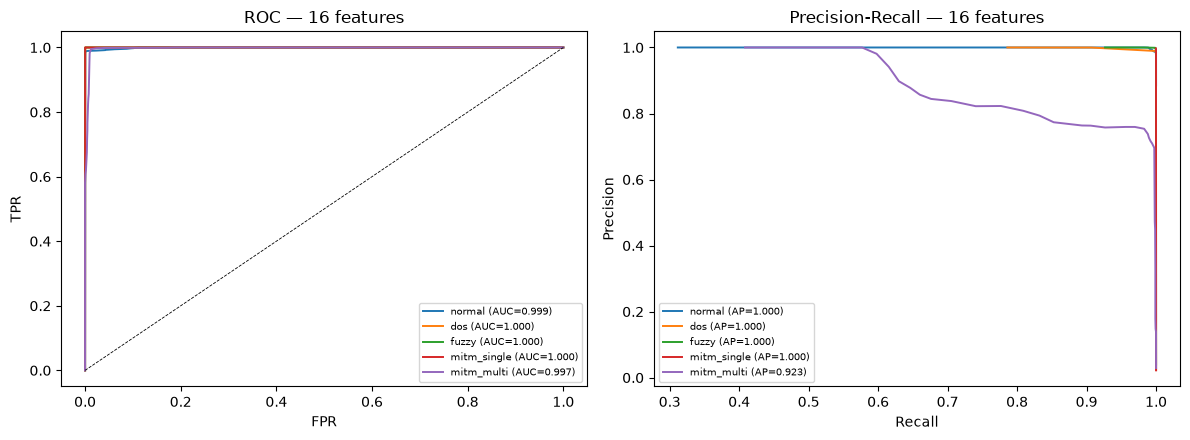

In [19]:
plot_roc_pr(resB)


## 7. Parte C — comparação 12 × 16 (ganho) e custo
O *ablation study*: o que as 4 *features* propostas acrescentam, e a que custo.


### 7.1 Ganho de detecção (F1 por classe e macro-F1)


In [20]:
cmp = pd.DataFrame([{"classe": c,
                     "F1 (12 feat)": resA["rep"][c]["f1-score"],
                     "F1 (16 feat)": resB["rep"][c]["f1-score"],
                     "Δ": resB["rep"][c]["f1-score"] - resA["rep"][c]["f1-score"]} for c in CLASSES])
cmp.loc[len(cmp)] = ["macro-F1", resA["macro_f1"], resB["macro_f1"], resB["macro_f1"]-resA["macro_f1"]]
cmp.round(4)


,classe,F1 (12 feat),F1 (16 feat),Δ
0,normal,0.9746,0.9935,0.0189
1,dos,0.8572,0.9965,0.1392
2,fuzzy,0.5450,0.9988,0.4538
3,mitm_single,0.9423,0.9930,0.0507
4,mitm_multi,0.5771,0.8380,0.2609
5,macro-F1,0.7793,0.9640,0.1847


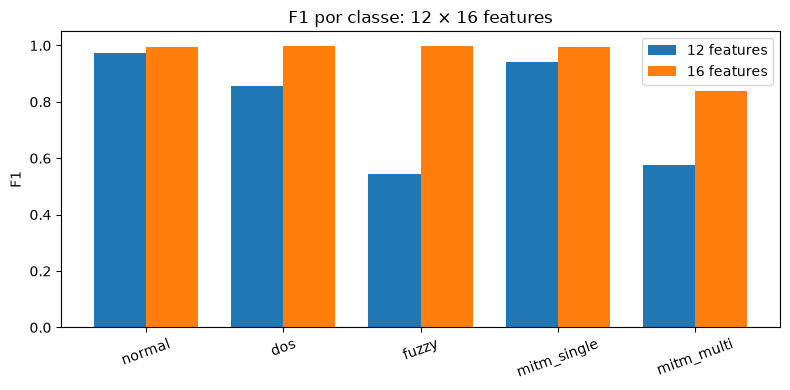

In [21]:
fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(NCLS); w = 0.38
ax.bar(x-w/2, [resA["rep"][c]["f1-score"] for c in CLASSES], w, label="12 features")
ax.bar(x+w/2, [resB["rep"][c]["f1-score"] for c in CLASSES], w, label="16 features")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=20); ax.set_ylabel("F1"); ax.set_ylim(0, 1.05)
ax.set_title("F1 por classe: 12 × 16 features"); ax.legend(); plt.tight_layout(); plt.show()


### 7.2 Custo — latência por estágio (1 núcleo, por pacote)
Medimos, pacote a pacote, os estágios do detector online: **layer** (parse), **feature**
(cálculo das features), **classification** (`inplace_predict` de 1 pacote) e **decision**
(argmax). Comparamos os dois modelos (12 e 16 features).


In [22]:
def measure_latency(clf, idx, pcap="data/pcap/benign_traffic.pcap", n=1000, warmup=2000):
    streamer = FeatureStreamer(); t_lay, t_fea, feats = [], [], []; k = 0
    for raw, meta in RawPcapReader(pcap):
        a = time.perf_counter(); p = parse(raw, _ts(meta)); b = time.perf_counter()
        if p is None: continue
        x = streamer.step(p, MODELS); c = time.perf_counter(); k += 1
        if k > warmup: t_lay.append(b-a); t_fea.append(c-b); feats.append(x)
        if len(feats) >= n: break
    Xs = ((np.asarray(feats, np.float64)-XMIN)/RNG).astype(np.float32)[:, idx]
    booster = clf.get_booster(); _ = booster.inplace_predict(Xs[:256])      # warm-up
    t_clf, t_dec = [], []
    for row in Xs:
        r = row.reshape(1, -1)
        a = time.perf_counter(); pr = booster.inplace_predict(r); b = time.perf_counter()
        _ = np.asarray(pr).argmax(-1); c = time.perf_counter(); t_clf.append(b-a); t_dec.append(c-b)
    us = lambda v: float(np.mean(v)*1e6)
    ext = us(t_lay)+us(t_fea); inf = us(t_clf)+us(t_dec)
    return {"layer": us(t_lay), "feature": us(t_fea), "classification": us(t_clf),
            "decision": us(t_dec), "extracao": ext, "inferencia": inf, "e2e": ext+inf,
            "pps": 1e6/(ext+inf)}
latA = measure_latency(resA["clf"], IDX_12); latB = measure_latency(resB["clf"], IDX_16)
pd.DataFrame([{"estágio": s, "12 feat (us)": latA[k], "16 feat (us)": latB[k]} for s, k in
             [("layer","layer"),("feature","feature"),("classification","classification"),
              ("decision","decision"),("EXTRAÇÃO","extracao"),("INFERÊNCIA","inferencia"),
              ("END-TO-END","e2e")]]).round(2)


,estágio,12 feat (us),16 feat (us)
0,layer,2.69,2.70
1,feature,14.01,14.04
2,classification,365.73,485.92
3,decision,1.05,1.09
4,EXTRAÇÃO,16.70,16.74
5,INFERÊNCIA,366.79,487.00
6,END-TO-END,383.49,503.74


As 4 *features* propostas acrescentam **pouco ou nenhum** custo de extração, e a inferência
é dominada pelo custo fixo da chamada do XGBoost (independente de 12 ou 16 *features*).
Ou seja: **ganho grande de detecção a custo de latência praticamente nulo.**


### 7.3 Custo sob orçamento de CPU — varredura de cota (estilo Kim)
Fixamos 1 núcleo e variamos a cota de CPU (`systemd-run`), emulando o orçamento de uma
ECU. Usamos o modelo de 16 *features* (a latência de 12 é praticamente igual). Requer
`sudo`/systemd (roda na VM).


>> cota 5%  (AllowedCPUs=0)


>> cota 10%  (AllowedCPUs=0)


>> cota 15%  (AllowedCPUs=0)


>> cota 20%  (AllowedCPUs=0)


>> cota 25%  (AllowedCPUs=0)


...

>> cota 200%  (AllowedCPUs=0-1)


>> cota 400%  (AllowedCPUs=0-3)


>> cota 800%  (AllowedCPUs=0-7)


salvo: results/latency_quota.json


,cota %,e2e us/pkt,pps
0,5,19904.2,50
1,10,8231.4,121
2,15,6110.1,164
3,20,3337.4,300
4,25,3435.1,291
5,30,2397.4,417
6,35,2127.0,470
7,40,2334.4,428
8,45,1797.7,556
9,50,1562.4,640


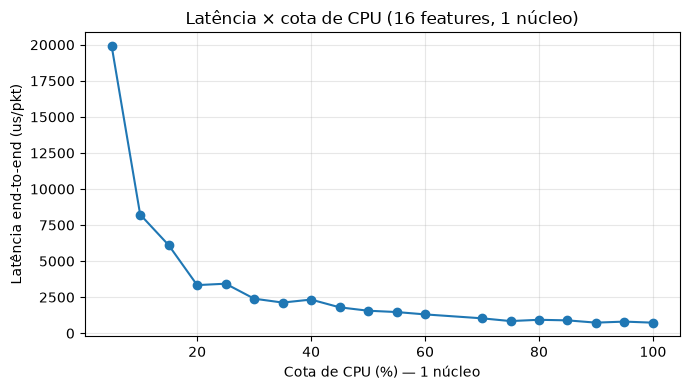

In [23]:
# Salva os artefatos do modelo de 16 features e roda a varredura de cota (script externo)
os.makedirs("results", exist_ok=True)
resB["clf"].save_model("results/model_16.json")
np.savez_compressed("results/bytemodels.npz", someip=MODELS["someip"].logP, sd=MODELS["sd"].logP, l4=MODELS["l4"].logP)
np.save("results/minmax.npy", np.vstack([XMIN, XMAX])); json.dump(IDX_16, open("results/content_idx.json", "w"))
os.system("bash scripts/cpu_quota.sh")
QP = "results/latency_quota.json"
if os.path.exists(QP):
    Q = json.load(open(QP)); q1 = [r for r in Q if r["allowed_cpus"] == "0"]
    dfq = pd.DataFrame([{"cota %": r["cpu_quota_pct"], "e2e us/pkt": round(r["latency"]["end_to_end_us_per_pkt"], 1),
                         "pps": round(r["latency"]["throughput_pps"])} for r in q1])
    display(dfq)
    plt.figure(figsize=(7, 4)); plt.plot(dfq["cota %"], dfq["e2e us/pkt"], "o-")
    plt.xlabel("Cota de CPU (%) — 1 núcleo"); plt.ylabel("Latência end-to-end (us/pkt)")
    plt.title("Latência × cota de CPU (16 features, 1 núcleo)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print("varredura indisponível (sem systemd/sudo) — rode na VM.")


## 8. Conclusão
Resumo da investigação (preenchido pela execução):


In [24]:
print("As 12 features do baseline, no multiclasse: macro-F1 = %.4f" % resA["macro_f1"])
print("  -> gargalos:  fuzzy F1=%.4f | mitm_multi F1=%.4f" % (resA["rep"]["fuzzy"]["f1-score"], resA["rep"]["mitm_multi"]["f1-score"]))
print("Com as 4 features propostas (16 no total):  macro-F1 = %.4f" % resB["macro_f1"])
print("  -> resolvido: fuzzy F1=%.4f | mitm_multi F1=%.4f" % (resB["rep"]["fuzzy"]["f1-score"], resB["rep"]["mitm_multi"]["f1-score"]))
print("Custo (1 núcleo): extração 12feat=%.1f vs 16feat=%.1f us/pkt | end-to-end 16feat=%.1f us/pkt (%.0f pps)"
      % (latA["extracao"], latB["extracao"], latB["e2e"], latB["pps"]))


As 12 features do baseline, no multiclasse: macro-F1 = 0.7793
  -> gargalos:  fuzzy F1=0.5450 | mitm_multi F1=0.5771
Com as 4 features propostas (16 no total):  macro-F1 = 0.9640
  -> resolvido: fuzzy F1=0.9988 | mitm_multi F1=0.8380
Custo (1 núcleo): extração 12feat=16.7 vs 16feat=16.7 us/pkt | end-to-end 16feat=503.7 us/pkt (1985 pps)
